### Stage 1 Model 1 — Predict coconut water-stress level

In [32]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib

from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, HistGradientBoostingClassifier,
    RandomForestRegressor
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, classification_report,
    ConfusionMatrixDisplay, confusion_matrix
)

print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

DATA_PATH = Path(
    "../data/coconut_health/stage1/data/cococare_stage1_outputs/stage1_hybrid_dataset.csv"
)

OUTPUT_DIR = Path("../results/coconut_health/stage1_result")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset exists:", DATA_PATH.exists())
print("Output folder:", OUTPUT_DIR.resolve())

pandas: 3.0.5
scikit-learn: 1.9.1
Dataset exists: True
Output folder: /home/sivabharathi/Documents/FinalYearProject/CocoCare/ml/results/coconut_health/stage1_result


<b>Loading the dataset  and audit the dataset</b> 

In [33]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

df = pd.read_csv(DATA_PATH)

required_columns = [
    "date", "rainfall_mm", "tmax_c", "tmin_c",
    "solar_radiation_mj_m2_day", "relative_humidity_pct",
    "wind_speed_m_s", "et0_mm_day",
    "etc_potential_mm_day_modelled",
    "water_stress_rule_derived"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
    print("Available columns:", df.columns.tolist())
    raise ValueError("Dataset schema does not match expectations.")

df["date"] = pd.to_datetime(df["date"], errors="coerce")

invalid_dates = df["date"].isna().sum()
missing_targets = df["water_stress_rule_derived"].isna().sum()

df = (
    df.dropna(subset=["date", "water_stress_rule_derived"])
      .sort_values("date")
      .reset_index(drop=True)
)

print("Dataset shape:", df.shape)
print("Invalid dates removed:", invalid_dates)
print("Missing targets removed:", missing_targets)
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Duplicate dates:", df["date"].duplicated().sum())
print("Total remaining missing cells:", df.isna().sum().sum())

print("\nTarget distribution:")
display(df["water_stress_rule_derived"].value_counts(dropna=False))
display(
    (df["water_stress_rule_derived"]
     .value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .to_frame("percent")
)

target = "water_stress_rule_derived"
print("\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values"))

Dataset shape: (365, 30)
Invalid dates removed: 0
Missing targets removed: 0
Date range: 2023-01-01 00:00:00 to 2023-12-31 00:00:00
Duplicate dates: 0
Total remaining missing cells: 0

Target distribution:


water_stress_rule_derived
low         197
high        125
moderate     43
Name: count, dtype: int64

,percent
water_stress_rule_derived,
low,53.97
high,34.25
moderate,11.78



Missing values by column:


,missing_values
date,0
rainfall_mm,0
tmax_c,0
tmin_c,0
solar_radiation_mj_m2_day,0
relative_humidity_pct,0
wind_speed_m_s,0
weather_source,0
weather_source_url,0
et0_mm_day,0


In [34]:
#Feature engineering and leakage prevention

df["day_sin"] = np.sin(2 * np.pi * df["date"].dt.dayofyear / 365.25)
df["day_cos"] = np.cos(2 * np.pi * df["date"].dt.dayofyear / 365.25)

for col in ["rainfall_mm", "etc_potential_mm_day_modelled"]:
    for window in [3, 7]:
        df[f"{col}_rolling{window}_prior"] = (
            df[col].shift(1).rolling(window=window, min_periods=window).mean()
        )

feature_columns = [
    "rainfall_mm", "tmax_c", "tmin_c", "solar_radiation_mj_m2_day",
    "relative_humidity_pct", "wind_speed_m_s", "et0_mm_day",
    "etc_potential_mm_day_modelled", "day_sin", "day_cos",
    "rainfall_mm_rolling3_prior", "rainfall_mm_rolling7_prior",
    "etc_potential_mm_day_modelled_rolling3_prior",
    "etc_potential_mm_day_modelled_rolling7_prior"
]

model_df = df.dropna(subset=feature_columns + [target]).copy().reset_index(drop=True)
X = model_df[feature_columns]
y = model_df[target].astype(str)
dates = model_df["date"]

print("Rows after creating lag features:", len(model_df))
print("Features:", len(feature_columns))
display(pd.DataFrame({"feature": feature_columns}))

Rows after creating lag features: 358
Features: 14


,feature
0,rainfall_mm
1,tmax_c
2,tmin_c
3,solar_radiation_mj_m2_day
4,relative_humidity_pct
5,wind_speed_m_s
6,et0_mm_day
7,etc_potential_mm_day_modelled
8,day_sin
9,day_cos


Chronological train/test split

In [35]:
split_idx = int(len(model_df) * 0.80)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
dates_train, dates_test = dates.iloc[:split_idx], dates.iloc[split_idx:]

print("Train dates:", dates_train.min(), "to", dates_train.max(), "| rows:", len(X_train))
print("Test dates :", dates_test.min(), "to", dates_test.max(), "| rows:", len(X_test))
print("\nTrain class distribution:")
display(y_train.value_counts().to_frame("count"))
print("\nTest class distribution:")
display(y_test.value_counts().to_frame("count"))

if y_train.nunique() < 2:
    raise ValueError("Training period has fewer than two classes; adjust the split carefully.")
if set(y_test.unique()) != set(y.unique()):
    warnings.warn(
        "The test period does not contain all target classes. Per-class metrics may be incomplete; "
        "do not use a random split just to improve scores. Consider a blocked/rolling time-series evaluation."
    )

Train dates: 2023-01-08 00:00:00 to 2023-10-20 00:00:00 | rows: 286
Test dates : 2023-10-21 00:00:00 to 2023-12-31 00:00:00 | rows: 72

Train class distribution:


,count
water_stress_rule_derived,
low,126
high,122
moderate,38



Test class distribution:


,count
water_stress_rule_derived,
low,71
moderate,1


/tmp/ipykernel_111505/3279899049.py:16: UserWarning: The test period does not contain all target classes. Per-class metrics may be incomplete; do not use a random split just to improve scores. Consider a blocked/rolling time-series evaluation.
  warnings.warn(


Define models to compare

In [36]:
models = {
    "Majority baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyClassifier(strategy="most_frequent"))
    ]),
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=3000, class_weight="balanced", random_state=42
        ))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            max_depth=4, min_samples_leaf=5, class_weight="balanced", random_state=42
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=3,
            class_weight="balanced_subsample", random_state=42, n_jobs=-1
        ))
    ]),
    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesClassifier(
            n_estimators=300, min_samples_leaf=3,
            class_weight="balanced", random_state=42, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(random_state=42)
    )]),
    "Support Vector Machine (RBF)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(class_weight="balanced", kernel="rbf", random_state=42))
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=7))
    ]),
    "Gaussian Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", GaussianNB())
    ])
}

print("Models:", len(models))
print("\nMetric priority: macro-F1 and balanced accuracy; accuracy is reported too.")

Models: 9

Metric priority: macro-F1 and balanced accuracy; accuracy is reported too.


Train and evaluate every model

In [37]:
results = []
fitted_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted_models[name] = model
    predictions[name] = pred

    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "macro_f1": f1_score(y_test, pred, average="macro", zero_division=0),
        "macro_precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, pred, average="macro", zero_division=0),
    })

results_df = pd.DataFrame(results).sort_values(
    ["macro_f1", "balanced_accuracy"], ascending=False
).reset_index(drop=True)

display(results_df.style.format({
    "accuracy": "{:.3f}", "balanced_accuracy": "{:.3f}",
    "macro_f1": "{:.3f}", "macro_precision": "{:.3f}", "macro_recall": "{:.3f}"
}))

results_df.to_csv(OUTPUT_DIR / "stage1_chronological_model_comparison.csv", index=False)
print("Saved:", OUTPUT_DIR / "stage1_chronological_model_comparison.csv")

/home/sivabharathi/miniconda3/envs/mldlenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/sivabharathi/miniconda3/envs/mldlenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/sivabharathi/miniconda3/envs/mldlenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/sivabharathi/miniconda3/envs/mldlenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/sivabharathi/miniconda3/envs/mldlenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: Use

,model,accuracy,balanced_accuracy,macro_f1,macro_precision,macro_recall
0,Majority baseline,0.986,0.500,0.497,0.493,0.500
1,Logistic Regression,0.986,0.500,0.333,0.333,0.333
2,Random Forest,0.917,0.465,0.321,0.333,0.310
3,Decision Tree,0.903,0.458,0.319,0.333,0.305
4,Extra Trees,0.889,0.451,0.316,0.333,0.300
5,Gaussian Naive Bayes,0.889,0.451,0.316,0.333,0.300
6,Gradient Boosting,0.861,0.437,0.311,0.333,0.291
7,Support Vector Machine (RBF),0.653,0.331,0.266,0.333,0.221
8,K-Nearest Neighbors,0.556,0.282,0.240,0.333,0.188


Saved: ../results/coconut_health/stage1_result/stage1_chronological_model_comparison.csv


Visualize the model comparison

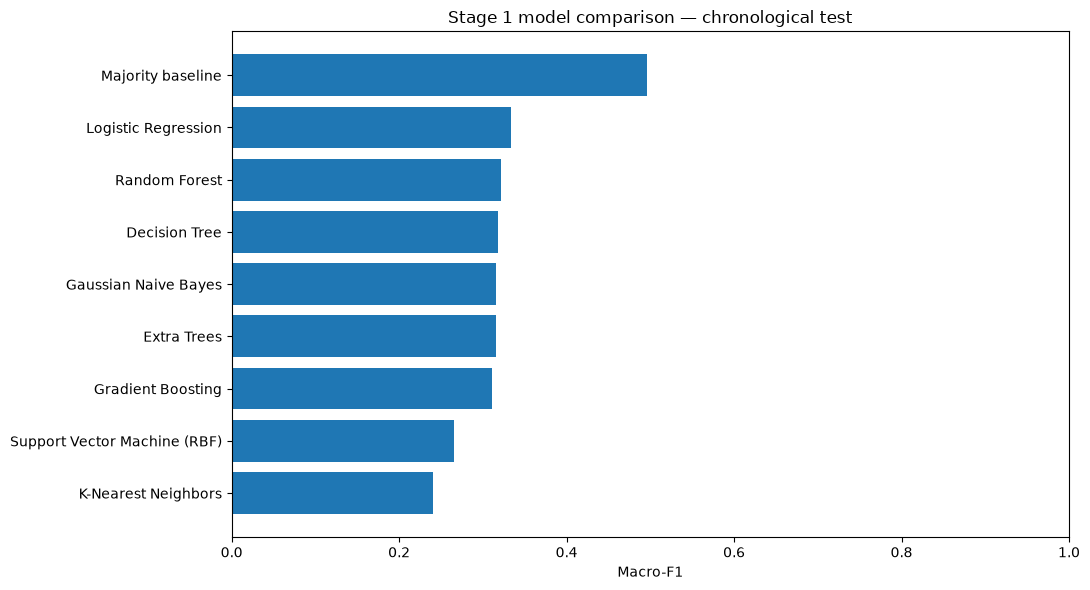

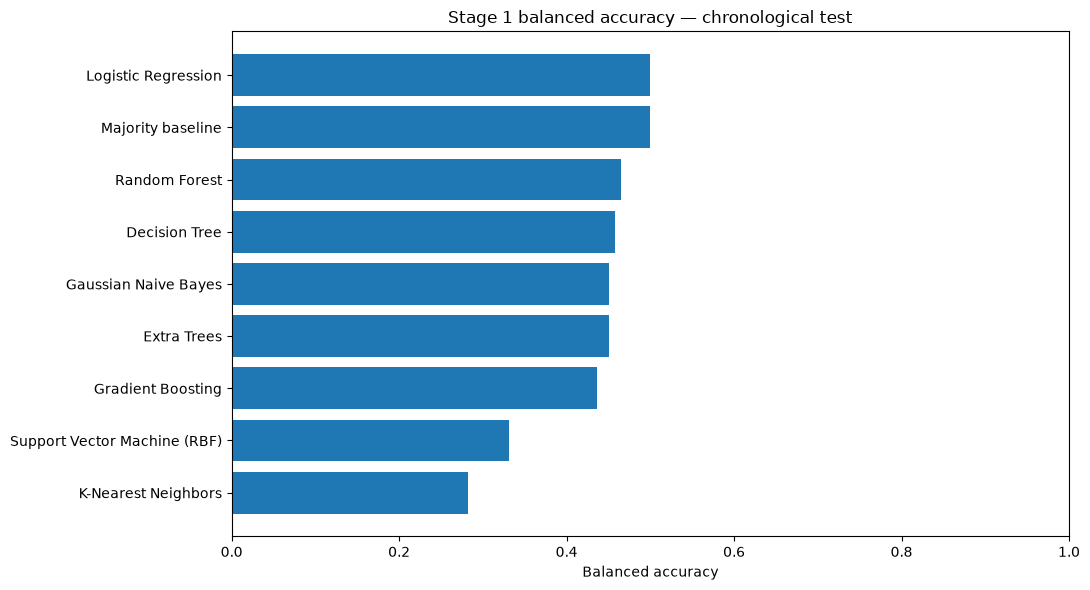

In [38]:
fig, ax = plt.subplots(figsize=(11, 6))
plot_df = results_df.sort_values("macro_f1", ascending=True)
ax.barh(plot_df["model"], plot_df["macro_f1"])
ax.set_xlabel("Macro-F1")
ax.set_title("Stage 1 model comparison — chronological test")
ax.set_xlim(0, 1)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "stage1_model_comparison_macro_f1.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(11, 6))
plot_df = results_df.sort_values("balanced_accuracy", ascending=True)
ax.barh(plot_df["model"], plot_df["balanced_accuracy"])
ax.set_xlabel("Balanced accuracy")
ax.set_title("Stage 1 balanced accuracy — chronological test")
ax.set_xlim(0, 1)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "stage1_model_comparison_balanced_accuracy.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

Detailed report for the leading model

Leading model by macro-F1: Majority baseline

Classification report:
              precision    recall  f1-score   support

         low       0.99      1.00      0.99        71
    moderate       0.00      0.00      0.00         1

    accuracy                           0.99        72
   macro avg       0.49      0.50      0.50        72
weighted avg       0.97      0.99      0.98        72



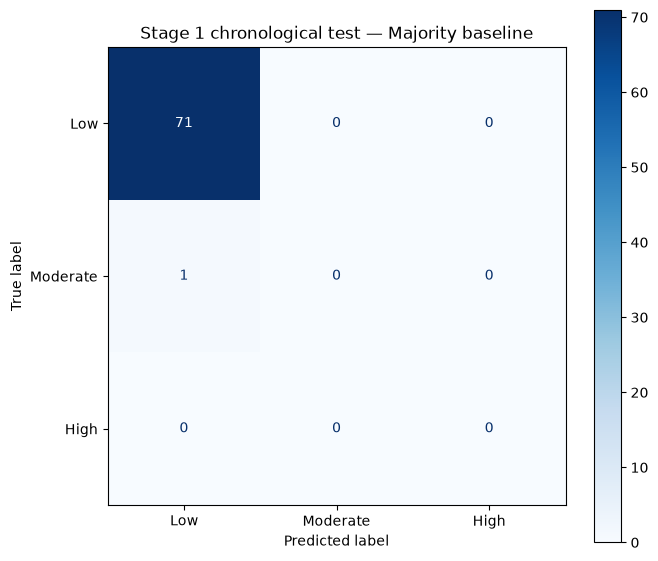

,date,actual,predicted
0,2023-10-21,low,low
1,2023-10-22,low,low
2,2023-10-23,low,low
3,2023-10-24,low,low
4,2023-10-25,low,low
5,2023-10-26,low,low
6,2023-10-27,low,low
7,2023-10-28,low,low
8,2023-10-29,low,low
9,2023-10-30,low,low


In [39]:
best_name = results_df.iloc[0]["model"]
best_model = fitted_models[best_name]
best_pred = predictions[best_name]

print("Leading model by macro-F1:", best_name)
print("\nClassification report:")
report_text = classification_report(y_test, best_pred, zero_division=0)
print(report_text)

report_dict = classification_report(y_test, best_pred, output_dict=True, zero_division=0)
(OUTPUT_DIR / "stage1_best_model_classification_report.json").write_text(
    json.dumps(report_dict, indent=2), encoding="utf-8"
)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, labels=["low", "moderate", "high"],
    display_labels=["Low", "Moderate", "High"], values_format="d", cmap="Blues", ax=ax
)
ax.set_title(f"Stage 1 chronological test — {best_name}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "stage1_best_model_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

predictions_df = pd.DataFrame({
    "date": dates_test.to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": best_pred
})
predictions_df.to_csv(OUTPUT_DIR / "stage1_best_model_test_predictions.csv", index=False)
display(predictions_df.head(15))

Feature importance / interpretation

,feature,importance_mean_macro_f1_drop,importance_std
0,rainfall_mm,0.0,0.0
1,tmax_c,0.0,0.0
2,tmin_c,0.0,0.0
3,solar_radiation_mj_m2_day,0.0,0.0
4,relative_humidity_pct,0.0,0.0
5,wind_speed_m_s,0.0,0.0
6,et0_mm_day,0.0,0.0
7,etc_potential_mm_day_modelled,0.0,0.0
8,day_sin,0.0,0.0
9,day_cos,0.0,0.0


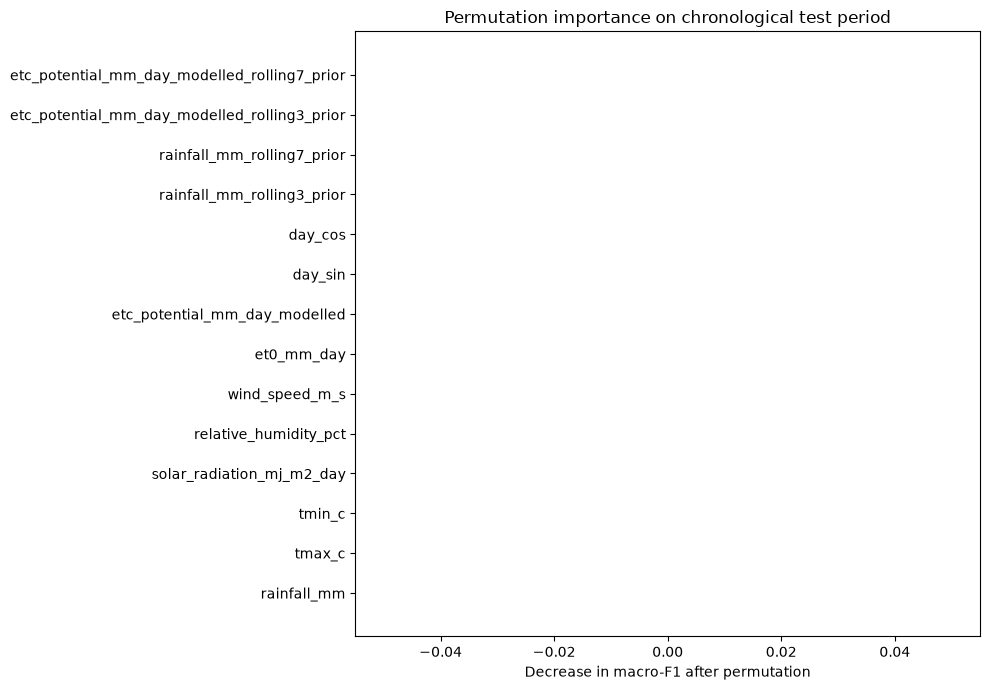

In [40]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=20, random_state=42, scoring="f1_macro", n_jobs=-1
)
importance_df = pd.DataFrame({
    "feature": feature_columns,
    "importance_mean_macro_f1_drop": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean_macro_f1_drop", ascending=False)
display(importance_df)

importance_df.to_csv(OUTPUT_DIR / "stage1_permutation_importance.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 7))
show = importance_df.sort_values("importance_mean_macro_f1_drop", ascending=True)
ax.barh(show["feature"], show["importance_mean_macro_f1_drop"])
ax.set_xlabel("Decrease in macro-F1 after permutation")
ax.set_title("Permutation importance on chronological test period")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "stage1_permutation_importance.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

Save the leading model and experiment metadata

In [41]:
artifact = {
    "model": best_model,
    "feature_columns": feature_columns,
    "target": target,
    "label_status": "rule_derived_not_ground_truth",
    "evaluation": "chronological first-80%-train / final-20%-test",
    "warning": (
        "Prototype research model. Labels are generated by a provisional simulation, "
        "not field observations; one-year data limits generalization."
    )
}
joblib.dump(artifact, OUTPUT_DIR / "stage1_water_stress_classifier_research.joblib")

metadata = {
    "dataset_path": str(DATA_PATH),
    "output_dir": str(OUTPUT_DIR),
    "source_rows": int(len(df)),
    "model_rows_after_lag_features": int(len(model_df)),
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "train_date_start": str(dates_train.min().date()),
    "train_date_end": str(dates_train.max().date()),
    "test_date_start": str(dates_test.min().date()),
    "test_date_end": str(dates_test.max().date()),
    "features": feature_columns,
    "target": target,
    "label_status": "rule_derived_not_ground_truth",
    "best_by_macro_f1": best_name,
    "metrics": results_df.to_dict(orient="records"),
    "limitations": [
        "Target labels are rule-derived, not measured ground truth.",
        "Only one year of weather data is available.",
        "A single chronological split may be sensitive to seasonal effects.",
        "Feature importance is not causal evidence.",
        "Model results do not establish agronomic accuracy."
    ]
}
(OUTPUT_DIR / "stage1_ml_experiment_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

print("Saved model, metrics, predictions, plots and metadata to:")
print(OUTPUT_DIR)
print("\nFiles:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p.name)

Saved model, metrics, predictions, plots and metadata to:
../results/coconut_health/stage1_result

Files:
- stage1_best_model_classification_report.json
- stage1_best_model_confusion_matrix.png
- stage1_best_model_test_predictions.csv
- stage1_chronological_model_comparison.csv
- stage1_ml_experiment_metadata.json
- stage1_model_comparison_balanced_accuracy.png
- stage1_model_comparison_macro_f1.png
- stage1_permutation_importance.csv
- stage1_permutation_importance.png
- stage1_water_stress_classifier_research.joblib


In [42]:

# Check the model comparison results
results_path = OUTPUT_DIR / "stage1_chronological_model_comparison.csv"

results = pd.read_csv(results_path)

display(
    results.sort_values("macro_f1", ascending=False)
    if "macro_f1" in results.columns
    else results
)

# Check the actual test-label distribution
print("\nActual test-label distribution:")
print(y_test.value_counts())

print("\nPredicted-label distribution for the selected model:")
print(pd.Series(best_model.predict(X_test)).value_counts())


,model,accuracy,balanced_accuracy,macro_f1,macro_precision,macro_recall
0,Majority baseline,0.986111,0.500000,0.496503,0.493056,0.500000
1,Logistic Regression,0.986111,0.500000,0.333333,0.333333,0.333333
2,Random Forest,0.916667,0.464789,0.321168,0.333333,0.309859
3,Decision Tree,0.902778,0.457746,0.318627,0.333333,0.305164
4,Extra Trees,0.888889,0.450704,0.316049,0.333333,0.300469
5,Gaussian Naive Bayes,0.888889,0.450704,0.316049,0.333333,0.300469
6,Gradient Boosting,0.861111,0.436620,0.310777,0.333333,0.291080
7,Support Vector Machine (RBF),0.652778,0.330986,0.265537,0.333333,0.220657
8,K-Nearest Neighbors,0.555556,0.281690,0.240240,0.333333,0.187793



Actual test-label distribution:
water_stress_rule_derived
low         71
moderate     1
Name: count, dtype: int64

Predicted-label distribution for the selected model:
low    72
Name: count, dtype: int64


In [43]:

# Stage 1: target-label and chronological split audit

df = pd.read_csv(DATA_PATH)

TARGET = "water_stress_rule_derived"
DATE_COL = "date"

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())

if TARGET not in df.columns:
    raise KeyError(f"Target column not found: {TARGET}")

if DATE_COL not in df.columns:
    raise KeyError(
        f"Date column '{DATE_COL}' not found. "
        "Check the actual date column name in df.columns."
    )

df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df = df.sort_values(DATE_COL).reset_index(drop=True)

print("\nOverall target distribution:")
print(df[TARGET].value_counts(dropna=False))

print("\nOverall target proportions:")
print(df[TARGET].value_counts(normalize=True, dropna=False).round(3))

print("\nDate range:")
print("Start:", df[DATE_COL].min())
print("End:  ", df[DATE_COL].max())

# Reproduce the chronological 80/20 split
split_idx = int(len(df) * 0.8)
train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

print("\nTraining period:")
print(train_df[DATE_COL].min(), "to", train_df[DATE_COL].max())

print("\nTraining label distribution:")
print(train_df[TARGET].value_counts(dropna=False))

print("\nTest period:")
print(test_df[DATE_COL].min(), "to", test_df[DATE_COL].max())

print("\nTest label distribution:")
print(test_df[TARGET].value_counts(dropna=False))

# Show the distribution by month
print("\nMonthly label counts:")
monthly_counts = pd.crosstab(
    df[DATE_COL].dt.to_period("M"),
    df[TARGET]
)
display(monthly_counts)

# Save the audit to the project results folder
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

monthly_counts.to_csv(OUTPUT_DIR / "stage1_monthly_label_counts.csv")
df[[DATE_COL, TARGET]].to_csv(
    OUTPUT_DIR / "stage1_target_label_audit.csv",
    index=False
)

print("\nAudit files saved in:", OUTPUT_DIR.resolve())


Dataset shape: (365, 30)

Columns: ['date', 'rainfall_mm', 'tmax_c', 'tmin_c', 'solar_radiation_mj_m2_day', 'relative_humidity_pct', 'wind_speed_m_s', 'weather_source', 'weather_source_url', 'et0_mm_day', 'etc_potential_mm_day_modelled', 'scenario', 'effective_rainfall_mm_modelled', 'runoff_mm_modelled', 'irrigation_mm_simulated', 'actual_et_mm_day_modelled', 'drainage_mm_modelled', 'soil_water_storage_mm_modelled', 'depletion_fraction_modelled', 'soil_moisture_vwc_pct_simulated', 'water_stress_rule_derived', 'recommended_action_simulated', 'model_status', 'location', 'latitude', 'longitude', 'variety', 'palm_age_months', 'data_class', 'stress_label_status']

Overall target distribution:
water_stress_rule_derived
low         197
high        125
moderate     43
Name: count, dtype: int64

Overall target proportions:
water_stress_rule_derived
low         0.540
high        0.342
moderate    0.118
Name: proportion, dtype: float64

Date range:
Start: 2023-01-01 00:00:00
End:   2023-12-31 00:

water_stress_rule_derived,high,low,moderate
date,,,
2023-01,27,0,4
2023-02,28,0,0
2023-03,31,0,0
2023-04,26,3,1
2023-05,3,15,13
2023-06,6,15,9
2023-07,0,31,0
2023-08,4,12,15
2023-09,0,30,0



Audit files saved in: /home/sivabharathi/Documents/FinalYearProject/CocoCare/ml/results/coconut_health/stage1_result
